# 27 — Cómo se reparte el día y de qué aseguradora llegan

## Pregunta y alcance

El cuaderno 26 midió qué tan bien se predice el **total** de solicitudes de triage de un día. Para el servicio de
urgencias el total no basta. Hace falta saber también:
- cómo se reparte ese total entre la madrugada, la mañana, la tarde y la noche;
- en qué horas se concentra la demanda;
- de qué aseguradora llegan los pacientes.

La aseguradora es además el primer eslabón de una cadena posterior: triage, consulta, hospitalización y especialidad.

Este cuaderno responde cuatro preguntas, cada una con una prueba fijada antes de calcular:

1. **El reparto del día.** ¿Con qué historia se estima mejor la forma del día, y cuánto error añade repartir?
2. **El rango del total.** ¿Se puede hacer más honesto el rango del día con los errores recientes?
3. **Las aseguradoras.** ¿Qué tan bien se predice cuántos pacientes llegan de cada grupo de aseguradora, y por
   jornada?
4. **La operación.** ¿Cómo se sostiene el pronóstico en el tiempo, y qué dijo la primera semana verificada antes de
   ocurrir?

Ninguna prueba reentrena el total del día. Todas usan las predicciones diarias ya guardadas de la validación semanal
de 2025 y 2026, a 1-7 y a 15-21 días de adelanto, con los modelos C0r y M3s. Se presenta M3s salvo que se indique
otra cosa; C0r da cifras casi idénticas.

## Contenido

1. La forma del día.
2. Qué perfil reparte mejor.
3. Cuánto error añade repartir: el piso de ruido.
4. La honestidad del rango por jornada.
5. Las horas de más demanda.
6. El rango del total no se arregla con los errores recientes.
7. De qué aseguradora llegan.
8. Nueva EPS: el cambio de nivel que ningún dato pasado anticipa.
9. La operación semanal y la primera semana verificada.
10. Conclusión.
11. Límites del análisis.

In [1]:
import sys, pathlib, warnings, json
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path[:0] = [str(RAIZ), str(RAIZ / "notebooks")]; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from IPython.display import Markdown, display
import statsmodels.api   # se importa antes: al importarse reinstala su filtro de avisos
import pronostico as pr, reparto as rp, aseguradoras as ag

AZUL, NARANJA, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
SECUENCIAL = ["#fcfcfb", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
MESES = ["", "ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
FR = {"madrugada": "Madrugada 0-6 h", "mañana": "Mañana 6-12 h", "tarde": "Tarde 12-18 h", "noche": "Noche 18-24 h"}
fmt = dict(precision=1, thousands=".", decimal=",")
R, A = rp.CARPETA, ag.CARPETA
for f in [R / "conteos.parquet", R / "rango_recalibrado.csv", A / "conteos.parquet"]:
    if not f.exists(): raise SystemExit(f"Falta {f.name}: python notebooks/reparto.py, reparto.py --rango y aseguradoras.py")
H = rp.horas()
Cr = pd.read_parquet(R / "conteos.parquet"); Ca = pd.read_parquet(A / "conteos.parquet")
print(f"Horas: {H.index.min().date()} a {H.index.max().date()}. Días evaluados en la validación: {Cr.fecha.nunique()}.")

Horas: 2020-01-01 a 2026-09-20. Días evaluados en la validación: 630.


---
# 1. La forma del día

Antes de predecir el reparto conviene ver qué tan marcada es la forma del día. La figura muestra la media de
solicitudes por hora en cada día de la semana durante el último año con datos.

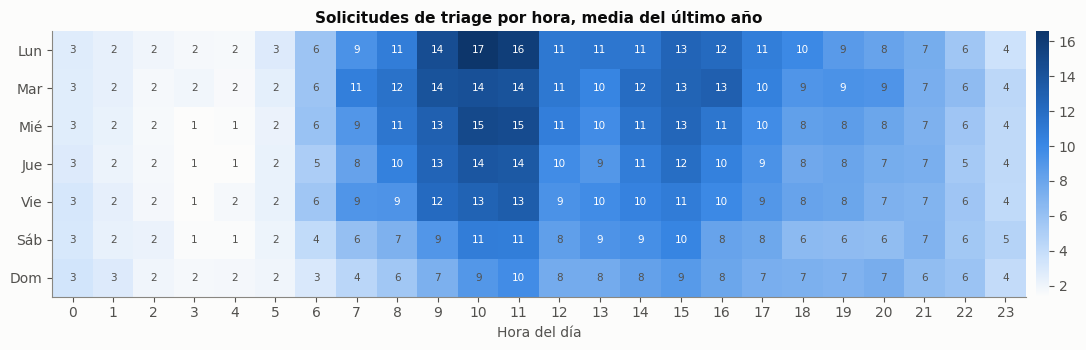

Pico: Lun a las 10 h (16.6/hora). Valle: Vie a las 3 h (1.4/hora). Oscilación: 12.1 veces.


In [2]:
u = H.loc[H.index.max() - pd.Timedelta(weeks=52):]
M = u.groupby(u.index.dayofweek).mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
from matplotlib.colors import LinearSegmentedColormap
im = ax.imshow(M.values, aspect="auto", cmap=LinearSegmentedColormap.from_list("s", SECUENCIAL))
ax.set_yticks(range(7), DIAS); ax.set_xticks(range(24), [f"{h}" for h in range(24)]); ax.grid(False)
for d in range(7):
    for h in range(24):
        v = M.values[d, h]; ax.text(h, d, f"{v:.0f}", ha="center", va="center", fontsize=7.5,
                                    color="white" if v > M.values.max() * .55 else TINTA2)
ax.set_xlabel("Hora del día"); ax.set_title("Solicitudes de triage por hora, media del último año")
plt.colorbar(im, ax=ax, fraction=.02, pad=.01).outline.set_visible(False); plt.tight_layout(); plt.show()
pico = M.stack().idxmax(); valle = M.stack().idxmin()
print(f"Pico: {DIAS[pico[0]]} a las {pico[1]} h ({M.values.max():.1f}/hora). Valle: {DIAS[valle[0]]} a las {valle[1]} h "
      f"({M.values.min():.1f}/hora). Oscilación: {M.values.max() / M.values.min():.1f} veces.")

A partir de la figura se observa que la forma del día es mucho más marcada que la diferencia entre días. La demanda
cae a uno o tres pacientes por hora en la madrugada, sube desde las 6 h y tiene **dos jorobas**:
- una entre las 9 y las 12 h;
- otra entre las 14 y las 17 h, separadas por un valle al mediodía.

Los fines de semana la primera joroba es más baja y la tarde se sostiene. Una forma tan estable sugiere que se estima
mejor con mucha historia que con pocas semanas recientes, y eso es lo que se probó.

---
# 2. Qué perfil reparte mejor

El perfil es la proporción del día que cae en cada hora, calculado solo con días anteriores al origen de la
predicción. Se compararon cuatro candidatos:
- P8, P26 y P52: la media de proporciones del mismo día de la semana en las últimas 8, 26 y 52 semanas. P8 era el
  reparto que se usaba hasta ahora.
- S26: la razón de sumas en 26 semanas.

Cada uno se probó también en una versión «F», en la que los festivos usan el perfil de los festivos anteriores.

La medida es la **distancia de variación total**: el porcentaje del día que queda asignado a horas equivocadas. La
elección se hizo en 2025, a 15 días de adelanto. Con diferencias menores de 0,1 puntos se elige el candidato más
simple.

In [3]:
Dd = pd.read_parquet(R / "distancias.parquet")
T = (Dd[Dd.combo == "M3s"].groupby(["candidato", "adelanto", "anio"]).tv.mean().unstack(["adelanto", "anio"]) * 100)
T.columns = [f"{a} días, {y}" for a, y in T.columns]
display(T.loc[["P8", "P26", "P52", "S26", "P8F", "P26F", "P52F", "S26F"]].style.format(precision=2, decimal=",")
        .highlight_min(axis=0, props="font-weight:bold"))

,"1 días, 2025","1 días, 2026","15 días, 2025","15 días, 2026"
candidato,,,,
P8,"13,36","14,89","13,58","14,80"
P26,"12,87","14,29","13,04","14,22"
P52,"12,76","14,19","12,93","14,10"
S26,"12,86","14,29","13,04","14,21"
P8F,"13,31","14,79","13,51","14,69"
P26F,"12,80","14,22","12,97","14,16"
P52F,"12,69","14,13","12,85","14,04"
S26F,"12,79","14,22","12,97","14,15"


Se descubrió que **P52 reparte mejor que el perfil de 8 semanas** en los cuatro cortes: 12,9 frente a 13,6 puntos en
2025 a 15 días. Separar los festivos mejora menos de 0,1 puntos, por debajo del umbral, así que se adopta P52 sin
regla de festivos. El orden confirma lo que sugería la figura: **la forma del día es estable**, y 8 días de un mismo
día de la semana son pocos para estimarla.

Una distancia de 13 puntos parece grande, pero casi todo es azar de llegadas. Con unos 175 pacientes repartidos en 24
horas, cada hora recibe entre 2 y 16; esa variación no la elimina ningún perfil. La sección siguiente lo separa.

---
# 3. Cuánto error añade repartir: el piso de ruido

El error de una jornada tiene tres fuentes:
1. el error del total del día;
2. el error de la forma;
3. el azar de las llegadas.

Para separarlas se calcularon, por jornada:
- el **error** con el total predicho;
- el **error con el total real**, que es solo el del reparto;
- el **piso de ruido**: el error que tendría quien conociera la tasa exacta de llegadas, por puro azar de conteo
  (Poisson).

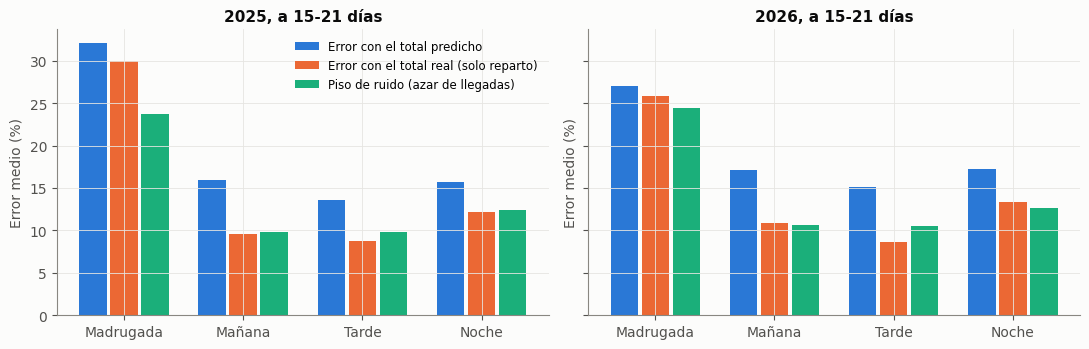

In [4]:
T = pd.read_csv(R / "resumen.csv", index_col=[0, 1, 2])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, anio in zip(axs, (2025, 2026)):
    t = T.loc[("M3s", 15, anio)]; x = np.arange(4); w = .26
    for k, (col, nom, c) in enumerate([("error %", "Error con el total predicho", AZUL),
                                       ("error con total real %", "Error con el total real (solo reparto)", NARANJA),
                                       ("piso de ruido %", "Piso de ruido (azar de llegadas)", AQUA)]):
        v = [t[f"{f}: {col}"] for f in FR]
        ax.bar(x + (k - 1) * w, v, w - .03, color=c, label=nom)
    ax.set_xticks(x, [FR[f].split(" ")[0] for f in FR]); ax.set_title(f"{anio}, a 15-21 días"); ax.set_ylabel("Error medio (%)")
axs[0].legend(loc="upper right", fontsize=8.5); plt.tight_layout(); plt.show()
tabla = pd.DataFrame({FR[f]: [T.loc[("M3s", 15, a)][f"{f}: {c}"] for a in (2025, 2026) for c in
                      ("media real", "error %", "error con total real %", "piso de ruido %")] for f in FR},
                     index=pd.MultiIndex.from_product([(2025, 2026), ("Pacientes", "Error %", "Error con total real %", "Piso %")]))
display(tabla.style.format(**fmt))

A partir de la gráfica se puede interpretar que **el reparto ya está en su límite**. En la mañana, la tarde y la
noche, el error con el total real coincide con el piso de ruido:
- la mañana tiene 9,6 % frente a 9,8 % en 2025;
- la tarde, 8,8 % frente a 9,8 %;
- la noche, 12,2 % frente a 12,4 %.

Ningún método de reparto puede bajar de ahí, porque lo que queda es azar de llegadas. Solo la madrugada queda unos 6
puntos por encima del piso, con 12 o 13 pacientes en seis horas.

El resto del error de cada jornada, que va del 14 al 17 %, viene del **total del día**. Para mejorar la predicción por
jornada hay que mejorar el total, no el reparto.

---
# 4. La honestidad del rango por jornada

Hasta ahora el rango de cada jornada se obtenía multiplicando el rango del día por la proporción de la jornada, como si
el reparto fuera seguro. El rango nuevo se construye de otra manera:
- se simula el total del día a partir de sus cuantiles;
- las proporciones salen de una distribución de Dirichlet, cuya dispersión se mide en el último año;
- las llegadas se cuentan con una multinomial.

Un rango del 80 % es honesto si contiene cerca del 80 % de los días.

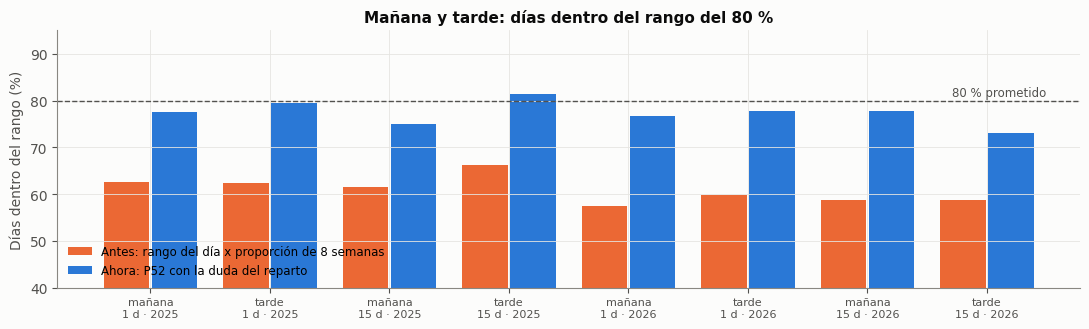

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.4))
etiquetas, antes, ahora = [], [], []
for anio in (2025, 2026):
    for lead in (1, 15):
        t = T.loc[("M3s", lead, anio)]
        for f in ("mañana", "tarde"):
            etiquetas.append(f"{f}\n{lead} d · {anio}"); antes.append(t[f"{f} con semana.py: en rango 80 %"]); ahora.append(t[f"{f}: en rango 80 %"])
x = np.arange(len(etiquetas))
ax.bar(x - .2, antes, .38, color=NARANJA, label="Antes: rango del día x proporción de 8 semanas")
ax.bar(x + .2, ahora, .38, color=AZUL, label="Ahora: P52 con la duda del reparto")
ax.axhline(80, color=TINTA2, lw=1, ls="--"); ax.text(len(x) - .5, 81, "80 % prometido", ha="right", fontsize=8.5, color=TINTA2)
ax.set_xticks(x, etiquetas, fontsize=8); ax.set_ylabel("Días dentro del rango (%)"); ax.set_ylim(40, 95)
ax.legend(loc="lower left", fontsize=8.5); ax.set_title("Mañana y tarde: días dentro del rango del 80 %")
plt.tight_layout(); plt.show()
cob = pd.DataFrame({FR[f]: [T.loc[("M3s", l, a)][f"{f}: en rango 80 %"] for a in (2025, 2026) for l in (1, 15)] for f in FR},
                   index=pd.MultiIndex.from_product([(2025, 2026), ("1-7 días", "15-21 días")]))
display(cob.style.format(**fmt))

Se descubrió que el rango anterior era **demasiado estrecho**: contenía solo entre el 58 y el 66 % de las mañanas y
tardes, frente al 80 % que anunciaba. Con la duda del reparto incluida, las cuatro jornadas quedan entre el 71 y el
83 %.

Los fallos que quedan se concentran en 2026 a 15-21 días: la tarde con un 73 % y la noche con un 71 %. Coinciden con
los días en que el rango del **total** falla, por los cambios de nivel de la red de salud que mostró el cuaderno 26.

---
# 5. Las horas de más demanda

Para cada día predicho se anuncia el bloque de tres horas consecutivas con más llegadas esperadas, uno en la mañana
(entre las 6 y las 13 h) y otro en la tarde (entre las 13 y las 20 h). Se cuenta un acierto cuando la hora real con
más llegadas de ese tramo cae dentro del bloque. La referencia es el bloque fijo más frecuente de 2024.

In [6]:
filas = []
for anio in (2025, 2026):
    for lead in (1, 15):
        t = T.loc[("M3s", lead, anio)]
        filas.append({"Año": anio, "Adelanto": f"{lead}-{lead + 6} días",
                      "Mañana: bloque más anunciado": t["bloque mañana: más elegido"], "Mañana: acierta %": t["bloque mañana: acierta %"],
                      "Mañana, bloque fijo de 2024: acierta %": t["bloque fijo mañana 9-12 h: acierta %"],
                      "Tarde: bloque más anunciado": t["bloque tarde: más elegido"], "Tarde: acierta %": t["bloque tarde: acierta %"],
                      "Tarde, bloque fijo de 2024: acierta %": t["bloque fijo tarde 14-17 h: acierta %"]})
display(pd.DataFrame(filas).style.format(**fmt).hide(axis="index"))

Año,Adelanto,Mañana: bloque más anunciado,Mañana: acierta %,"Mañana, bloque fijo de 2024: acierta %",Tarde: bloque más anunciado,Tarde: acierta %,"Tarde, bloque fijo de 2024: acierta %"
2.025,1-7 días,9-12 h,"86,8","87,1",14-17 h,"79,9","80,8"
2.025,15-21 días,9-12 h,"86,0","86,5",14-17 h,"78,8","80,2"
2.026,1-7 días,9-12 h,"85,7","85,3",14-17 h,"71,4","69,5"
2.026,15-21 días,9-12 h,"86,1","85,7",14-17 h,"71,8","69,8"


Se descubrió que las horas de más demanda son **un rasgo fijo del servicio**:
- en la mañana, el bloque de 9 a 12 h contiene la hora pico el 86 % de los días;
- en la tarde, el de 14 a 17 h la contiene entre el 71 y el 80 %.

El perfil acierta igual que el bloque fijo de 2024 porque casi siempre anuncia ese mismo bloque. Solo los fines de
semana lo corre una hora. Para el servicio la lectura es sencilla: **la saturación de la mañana se concentra de 9 a
12 h y la de la tarde de 14 a 17 h**. No es un aviso sobre un día concreto, y así debe comunicarse.

---
# 6. El rango del total no se arregla con los errores recientes

Como el error que queda viene del total del día, se probó la corrección más barata y la más fácil de sostener sin
supervisión: un posproceso que ajusta el rango con los errores ya conocidos en el origen, en las últimas 8 semanas.
- **R1** lo ensancha o lo estrecha según la dispersión reciente de los errores.
- **R2** además lo desplaza según su sesgo reciente.
- **R0** no cambia nada.

La elección se hizo con el puntaje de cuantiles de 2025 a 15 días.

In [7]:
Rg = pd.read_csv(R / "rango_recalibrado.csv", index_col=[0, 1, 2, 3])
cols = ["puntaje cuantiles %", "error del dia %", "cobertura 80 %", "p Kupiec", "P(fuera | ayer fuera) %"]
t = Rg.xs(("M3s", 15), level=["combo", "adelanto"])[cols]
t.columns = ["Puntaje de cuantiles %", "Error del día %", "Dentro del rango %", "p de Kupiec", "Fuera, si ayer fuera %"]
display(t.style.format(precision=2, decimal=","))

Se descubrió que **las dos correcciones empeoran**:
- **R1**: el puntaje pasa de 2,58 a 2,63 y la cobertura de 2026 baja del 71 al 68 %;
- **R2**: el puntaje llega a 2,70 y la cobertura de 2026 al 62 %.

La última columna explica por qué. Cuando un día cae fuera del rango, el siguiente también cae fuera entre el 41 y el
62 % de las veces, cuando lo esperado es el 20 %. **Los fallos llegan en racha y sin aviso.** Las semanas previas a un
salto de nivel suelen ser tranquilas, así que R1 estrecha el rango justo antes de que haga falta ensancharlo. R2 corrige
el nivel con 15 días de retraso y persigue un cambio que ya pasó.

La conclusión es que el rango del total **no se arregla mirando los propios errores**. Los saltos de nivel solo se
anticipan con una señal externa conocida antes.

---
# 7. De qué aseguradora llegan

Las solicitudes se agruparon en ocho grupos de aseguradora. Las agrupaciones se hicieron por el nombre de la entidad
administradora, y todos los conteos son agregados. La figura muestra la media mensual por día de los dos grupos
grandes y del resto.

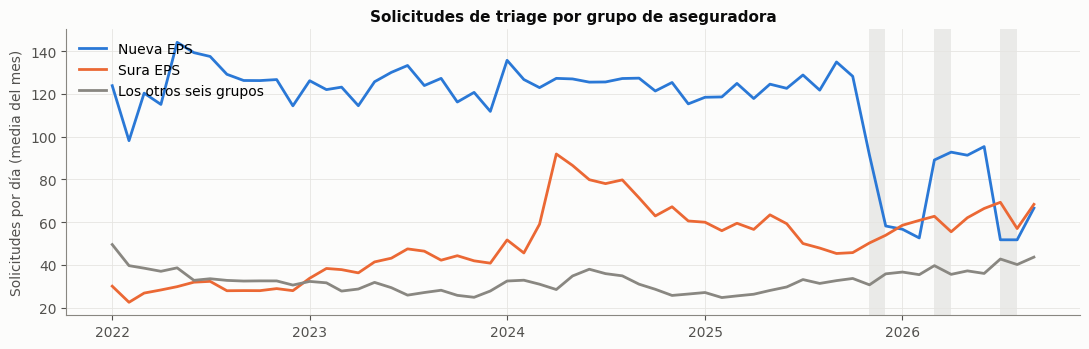

,Por día en 2026,Del total %
Nueva EPS,"72,2","41,8"
Sura EPS,"62,0","35,9"
Régimen especial,"9,7","5,6"
Otras EPS,"8,0","4,6"
SOAT (tránsito),"7,7","4,5"
Otros,"6,5","3,8"
Prepagada,"4,2","2,4"
ARL (laboral),"2,3","1,3"


In [8]:
dias_g, Xg = ag.conteos_grupo()
G = pd.DataFrame(Xg.sum(1), index=dias_g, columns=ag.GRUPOS).loc["2022":"2026-09-20"]
Mm = G.resample("MS").mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(Mm.index, Mm.nueva_eps, color=AZUL, lw=2, label="Nueva EPS")
ax.plot(Mm.index, Mm.sura_eps, color=NARANJA, lw=2, label="Sura EPS")
ax.plot(Mm.index, Mm.drop(columns=["nueva_eps", "sura_eps"]).sum(1), color=MUDO, lw=2, label="Los otros seis grupos")
for m in ["2025-11", "2026-03", "2026-07"]:
    ax.axvspan(pd.Timestamp(m), pd.Timestamp(m) + pd.offsets.MonthEnd(1), color=MUDO, alpha=.15, lw=0)
ax.set_ylabel("Solicitudes por día (media del mes)"); ax.legend(loc="upper left"); ax.set_title("Solicitudes de triage por grupo de aseguradora")
plt.tight_layout(); plt.show()
media = G.loc["2026"].mean().rename(ag.NOMBRES).sort_values(ascending=False)
display(pd.DataFrame({"Por día en 2026": media, "Del total %": 100 * media / media.sum()}).style.format(**fmt))

A partir de la gráfica se puede interpretar que la mezcla de aseguradoras **cambia rápido y a saltos**. Nueva EPS pasa
de 128 solicitudes por día en octubre de 2025 a 58 en diciembre, vuelve a 89 en marzo de 2026, cae a 52 en julio y
sube a 66 en septiembre. Las franjas sombreadas marcan esos meses de cambio. Sura tuvo su propio salto en abril de 2024,
de 59 a 92 por día, y bajó después de forma gradual hasta unos 46 a fines de 2025. Desde entonces vuelve a crecer, y en
2026 los dos grupos llegan a pesar casi lo mismo. Los otros seis grupos suman entre 30 y 45 por día en 2025-2026 y se mueven poco.

Una mezcla que cambia así se estima mejor con poca historia reciente, al revés que la forma del día. Para cada día
predicho se probaron seis ventanas: todos los días de las últimas 4, 8, 13 o 26 semanas (T4 a T26), o solo el mismo
día de la semana (D8 y D26). El reparto por jornada encadena la simulación del total del día, la de las jornadas y la
de las aseguradoras dentro de cada jornada.

In [9]:
el = (A / "eleccion.txt").read_text(encoding="utf-8").splitlines()
print(f"Elegido: {el[0]}"); print("\n".join(el[1:]))
Ta = pd.read_csv(A / "resumen.csv", index_col=[0, 1, 2, 3])
filas = []
for g in ag.GRUPOS:
    f = {"Grupo": ag.NOMBRES[g]}
    for anio in (2025, 2026):
        t = Ta.loc[("M3s", 15, anio, g)]
        f |= {f"Por día {anio}": t["media real"], f"Error en pacientes {anio}": t["error absoluto"],
              f"Error % {anio}": t["error %"], f"Piso % {anio}": t["piso de ruido %"], f"Dentro del rango % {anio}": t["en rango 80 %"]}
    filas.append(f)
display(pd.DataFrame(filas).style.format(**fmt).hide(axis="index"))

Elegido: T4
T4     7.8278
T8     8.3934
T13    8.7265
T26    8.9434
D8     8.5065
D26    8.9402


Grupo,Por día 2025,Error en pacientes 2025,Error % 2025,Piso % 2025,Dentro del rango % 2025,Por día 2026,Error en pacientes 2026,Error % 2026,Piso % 2026,Dentro del rango % 2026
Nueva EPS,"113,9","15,3","17,9","7,8","74,7","72,8","16,1","25,1","9,7","53,6"
Sura EPS,"53,7","7,6","14,8","11,1","80,2","62,4","8,7","14,9","10,3","79,4"
Otras EPS,"6,7","2,5","53,6","32,9","77,5","7,9","2,7","48,2","30,4","81,7"
Régimen especial,"6,6","2,2","48,7","33,3","86,3","9,8","3,2","43,5","27,6","75,8"
SOAT (tránsito),"6,1","2,7","72,1","36,8","74,7","7,6","2,7","50,7","30,9","77,8"
ARL (laboral),"1,7","1,1","62,8","55,4","92,3","2,3","1,4","70,6","53,9","88,1"
Prepagada,"2,5","1,3","57,1","50,0","87,9","4,2","1,6","53,8","41,5","88,9"
Otros,"6,7","2,9","67,2","34,6","74,5","6,4","2,9","69,8","35,3","75,0"


Se descubrió que gana **T4**, la ventana más corta: reparte mal 7,8 puntos frente a 8,4 a 8,9 de las demás.

Los resultados a 15-21 días separan tres situaciones:
- **Sura se predice bien.** Tiene un error del 15 %, poco por encima del piso de ruido de 10-11 % más el error del
  día, y su rango contiene el 79-80 % de los días en los dos años. Por jornada queda entre el 77 y el 87 %.
- **Los grupos pequeños** (otras EPS, régimen especial, SOAT, ARL, prepagada y otros) traen entre 2 y 10 pacientes al
  día. Su error relativo parece alto, del 43 al 72 %, pero en pacientes es de 1 a 3 por día, muy cerca de su piso de
  ruido. Se informan como rango.
- **Nueva EPS no se predice bien en 2026**: error del 25 % y solo el 54 % de los días dentro del rango.

---
# 8. Nueva EPS: el cambio de nivel que ningún dato pasado anticipa

La figura muestra, semana a semana, qué parte de los días de Nueva EPS cayó dentro del rango a 15-21 días. Las franjas
sombreadas son los meses de cambio de su convenio.

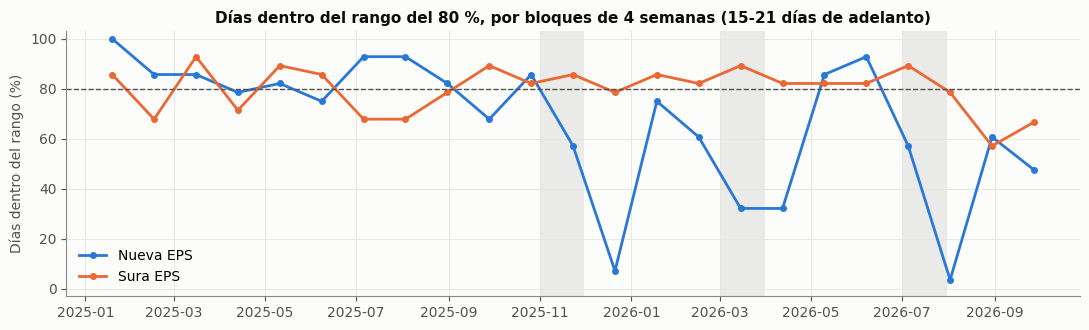

Nueva EPS dentro del rango: 15 % en los meses de cambio y 75 % en el resto. Sura: 84 % y 79 %.


In [10]:
c = Ca[(Ca.combo == "M3s") & (Ca.adelanto == 15)].copy()
c["dentro"] = (c.nueva_eps_real >= c.nueva_eps_q10) & (c.nueva_eps_real <= c.nueva_eps_q90)
c["dentro_s"] = (c.sura_eps_real >= c.sura_eps_q10) & (c.sura_eps_real <= c.sura_eps_q90)
s = c.groupby(pd.Grouper(key="fecha", freq="4W")).agg(nueva=("dentro", "mean"), sura=("dentro_s", "mean"))
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(s.index, 100 * s.nueva, color=AZUL, lw=2, marker="o", ms=4, label="Nueva EPS")
ax.plot(s.index, 100 * s.sura, color=NARANJA, lw=2, marker="o", ms=4, label="Sura EPS")
for m in ["2025-11", "2026-03", "2026-07"]:
    ax.axvspan(pd.Timestamp(m), pd.Timestamp(m) + pd.offsets.MonthEnd(1), color=MUDO, alpha=.15, lw=0)
ax.axhline(80, color=TINTA2, lw=1, ls="--"); ax.set_ylim(-3, 103)
ax.set_ylabel("Días dentro del rango (%)"); ax.legend(loc="lower left"); ax.set_title("Días dentro del rango del 80 %, por bloques de 4 semanas (15-21 días de adelanto)")
plt.tight_layout(); plt.show()
cm = c.fecha.dt.strftime("%Y-%m").isin(ag.CAMBIOS_NE)
print(f"Nueva EPS dentro del rango: {100 * c.dentro[cm].mean():.0f} % en los meses de cambio y {100 * c.dentro[~cm].mean():.0f} % en el resto. "
      f"Sura: {100 * c.dentro_s[cm].mean():.0f} % y {100 * c.dentro_s[~cm].mean():.0f} %.")

A partir de la gráfica se puede interpretar que **la falla del total y la de Nueva EPS son la misma**. En los meses de
cambio de su convenio, el rango de Nueva EPS se vacía: solo el 15 % de los días cae dentro (el 5 % en 2026),
mientras Sura sigue cerca del 80 %. Fuera de esos meses, Nueva EPS queda en el 75 %, cerca de Sura.

Los saltos responden a suspensiones y reanudaciones de la atención, que se deciden fuera del hospital y no dejan rastro
previo en el triage. Por eso ninguna ventana de datos pasados los anticipa, como tampoco los anticipó la corrección del
rango de la sección 6.

**La única variable que puede corregirlo es el estado del convenio con fecha, conocido antes.** Un nombre de
aseguradora en cada solicitud no aporta esa información: la columna de aseguradora añadida a la base coincide fila por
fila con el nombre de la entidad que ya se usaba.

---
# 9. La operación semanal y la primera semana verificada

Para que el pronóstico se sostenga en el tiempo, el ciclo semanal sigue estos pasos:
1. bajar los conteos agregados;
2. reentrenar desde cero con **receta fija**: las variables y los parámetros no se vuelven a elegir, solo se actualizan
   los datos;
3. predecir los 28 días siguientes y guardar la predicción;
4. verificar las anteriores;
5. calcular un semáforo con cuatro señales: la antigüedad de los datos, el error reciente, la honestidad reciente del
   rango y el cambio de nivel de Nueva EPS.

Se adopta el modelo C0r, que usa calendario, estación, nivel y memoria. Hay tres razones:
- no depende de calendarios mantenidos a mano, que dejan de actualizarse sin aviso;
- en la prueba de sesgo de selección del cuaderno 26, M3 no se separa de C0r;
- en la semana verificada, la diferencia fue de medio punto.

### La semana del 5 al 11 de octubre de 2026

Esta predicción se guardó el 6 de octubre con datos hasta el 20 de septiembre: entre 15 y 21 días antes de cada día.
Los valores reales se contaron después en la base, y ningún modelo los vio.

Modelo,Media anunciada,Media real,Error del día %,Días dentro del rango
M3s,"177,7","177,4","6,8",7 de 7
C0r,"177,9","177,4","7,3",7 de 7


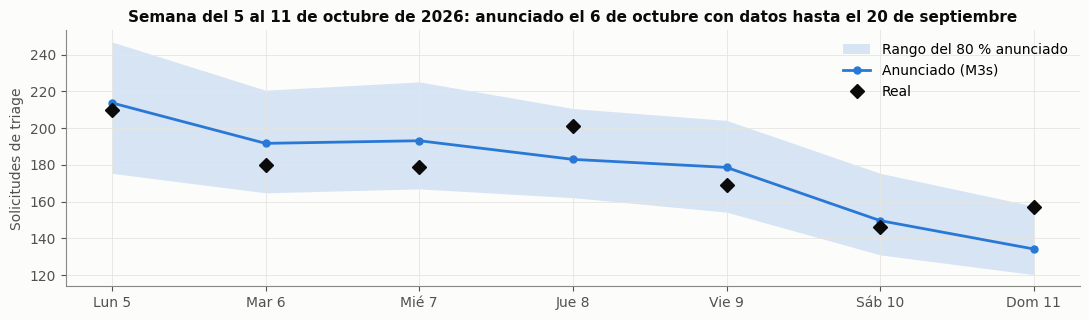

In [11]:
rep = pd.read_csv(RAIZ / "datos/triage_reportado.csv", parse_dates=["fecha"])
real = rep[rep.fuente.str.startswith("conteo agregado")].set_index("fecha").triages
filas = []
for m in ("M3s", "C0r"):
    S = pd.read_csv(pr.SALIDA / "semanal" / f"semana_2026-10-05_{m}.csv", parse_dates=["fecha"]).set_index("fecha")
    r = real.reindex(S.index)
    filas.append({"Modelo": m, "Media anunciada": S.q50.mean(), "Media real": r.mean(), "Error del día %": (100 * (S.q50 - r).abs() / r).mean(),
                  "Días dentro del rango": f"{int(((r >= S.q10) & (r <= S.q90)).sum())} de 7"})
display(pd.DataFrame(filas).style.format(**fmt).hide(axis="index"))
S = pd.read_csv(pr.SALIDA / "semanal" / "semana_2026-10-05_M3s.csv", parse_dates=["fecha"]).set_index("fecha")
fig, ax = plt.subplots(figsize=(11, 3.3)); x = np.arange(7)
ax.fill_between(x, S.q10, S.q90, color=AZUL, alpha=.18, lw=0, label="Rango del 80 % anunciado")
ax.plot(x, S.q50, color=AZUL, lw=2, marker="o", ms=5, label="Anunciado (M3s)")
ax.plot(x, real.reindex(S.index).values, color=TINTA, lw=0, marker="D", ms=7, label="Real")
ax.set_xticks(x, [f"{DIAS[t.dayofweek]} {t.day}" for t in S.index]); ax.set_ylabel("Solicitudes de triage")
ax.legend(loc="upper right"); ax.set_title("Semana del 5 al 11 de octubre de 2026: anunciado el 6 de octubre con datos hasta el 20 de septiembre")
plt.tight_layout(); plt.show()

Se descubrió que la primera semana verificada de forma prospectiva salió bien:
- M3s anunció una media de 178 solicitudes por día y la real fue de 177,4;
- los 7 días cayeron dentro del rango, con un error medio del 6,8 %;
- C0r anunció 180, con un error del 7,3 % y también 7 de 7 días dentro.

El único día alejado fue el domingo 11, víspera del festivo del lunes 12: se anunciaron 134 y llegaron 157, sobre todo
en la mañana. El lunes festivo se anunció en 155 y llegaron 158.

Fue una semana sin cambios en la red de salud, que es justo la situación en la que el modelo funciona bien según todo
lo anterior. Una semana no prueba la madurez. Confirma que, en ausencia de choques, el pronóstico a tres semanas acierta
el nivel.

---
# 10. Conclusión

1. **El reparto del día está resuelto.** La forma del día se estima mejor con un año de historia (P52). Su error
   coincide con el azar de las llegadas, y ningún método puede bajar de ahí. El rango por jornada pasó de contener el
   58-66 % de los días al 71-83 %.
2. **Las horas de más demanda son fijas**: de 9 a 12 h y de 14 a 17 h, con aciertos del 86 % y del 71-80 %. Se
   comunican como rasgo del servicio, no como aviso de un día concreto.
3. **De qué aseguradora llegan se puede informar**:
   - Sura, por día y por jornada, con rango honesto;
   - los grupos pequeños, en rango, con errores de 1 a 3 pacientes al día;
   - Nueva EPS solo fuera de sus cambios de convenio.
4. **El error que queda tiene un solo origen: los cambios de nivel de la red de salud**, sobre todo los de Nueva EPS.
   No se corrigen con los errores recientes ni con otra ventana de datos. Requieren una señal externa conocida antes:
   **el estado del convenio de cada aseguradora, con fecha**.
5. **La primera semana prospectiva acertó** el nivel con un error del 6,8 % y 7 de 7 días dentro del rango.

---
# 11. Límites del análisis

- **Todo se evaluó sobre predicciones diarias ya guardadas.** El total del día no se reentrenó, así que el reparto
  hereda las virtudes y los defectos de esas predicciones.
- **La validación reajusta los modelos cada cuatro domingos**; la operación reentrena cada semana. Es una diferencia
  pequeña y a favor de la operación.
- **2026 se miró después de elegir en 2025**, una sola vez, en las tres pruebas. La elección del perfil y de la ventana
  de aseguradoras no usó 2026.
- **La clasificación de aseguradoras se hizo por nombre** y agrupa entidades distintas bajo un mismo grupo (por
  ejemplo, varios códigos de Nueva EPS). Un error de clasificación movería pacientes entre grupos, pero no el total.
- **El piso de ruido supone llegadas de Poisson** con la tasa igual al valor observado. Es una aproximación: la
  sobredispersión real lo haría algo más alto.
- **La semana prospectiva es una sola** y sin choques de la red de salud. Sus conteos reales se tomaron de la base el
  13 de octubre de 2026; el reporte interno del hospital para la semana anterior da entre un 3 y un 8 % menos, por una
  diferencia de criterio que no se ha aclarado.
- **Los meses de cambio de Nueva EPS se identificaron con los datos** (noviembre de 2025, marzo y julio de 2026). Sirven
  para describir la falla, no para anticiparla.